### ASTR 3300: Astrostatistics
***N. Pol***
___

# Homework 5
### Due: Tuesday, Oct. 27, 11:59 pm CST
---

## Only one problem this week

This problem uses a dataset in `/coursework/homeworks/hw_data/`.

1) Read in `hw5_data_1.npy`. This is a (100 x 3) numpy array, containing some time-series measurements. It could be flux measurements from a star or some other transient. The first column is time (arbitrary units), the second column is the flux (arbitrary units), and the third column are homoescedastic measurement uncertainties on the flux. Plot this data with the uncertainties.

2) One possible model for this data is a sharp burst with an exponential tail rising above a nominal background level. This model can be described as:

$y = b$, for $t<t_0$

$y = b + A\exp[-\alpha(t-t_0)]$, for $t\geq t_0$

where $b$ is the background amplitude, $A$ is the burst amplitude, $t_0$ is the burst epoch, and $\alpha$ encodes how rapidly the burst dies off.

Code this burst model, and code a likelihood function for this data with the burst model. *Hint: This is similar in spirit to the likelihood when fitting polynomials to data, except now $x$ is time, and the polynomial model is now the burst model.* 

3) Using one of the MCMC codes that we looked at in class (`emcee`, `pymc3`, `PTMCMCSampler`) perform a Bayesian analysis that recovers an MCMC chain of posterior probability samples for the joint parameter space of $\{b,A,t_0,\alpha\}$. You must decide on how many samples are appropriate for running your MCMC. For your priors, make them $b\in \mathrm{Uniform}[0,50]$, $A\in \mathrm{Uniform}[0,50]$, $t_0\in \mathrm{Uniform}[0,100]$, and $\ln\alpha\in \mathrm{Uniform}[-5,5]$.

4) Perform an appropriate check to burn-in your chain, and thin the chain by selecting only points every auto-correlation length. If you are left with a small number of samples after thinning then you may need to run your MCMC for longer in (3).

5) Make a corner plot of the $4$-D parameter space, with labels, $[68,95]\%$ credible levels and quantiles, and titles.

6) Now choose $100$ samples randomly from your burned, thinned chain and plot the $100$ corresponding burst time-series on a figure along with the original data. You may want to choose a transparency for these $100$ burst curves that allows you to see everything nicely. These are showing the posterior spread of model solutions that are consistent with the data.

7) Another possible model that may explain the data is a Gaussian profile described by:

$y = b + A\exp[-(t-t_0)^2 / 2\sigma_W^2]$

The priors for this model are the same as above for the equivalent parameters, and with $\ln\sigma_W\in\mathrm{Uniform}[-2,2]$. Following the examples from `Lecture 12` and from relevant web tutorials/documentation, use one of the nested sampling packages (`dynesty` or `UltraNest`) to compute the Bayesian evidence for this Gaussian model, and for the original burst model. Compute the Bayes factor, and state which model is the favored description of the data. *Hint: Be careful with how you transform your parameter space into a unit hypercube for the nested sampling priors. An appropriate check on whether you have done things correctly is that the posterior samples you get from the burst analysis here should give an equivalent corner plot to the MCMC you did above.*

### Solution

1.

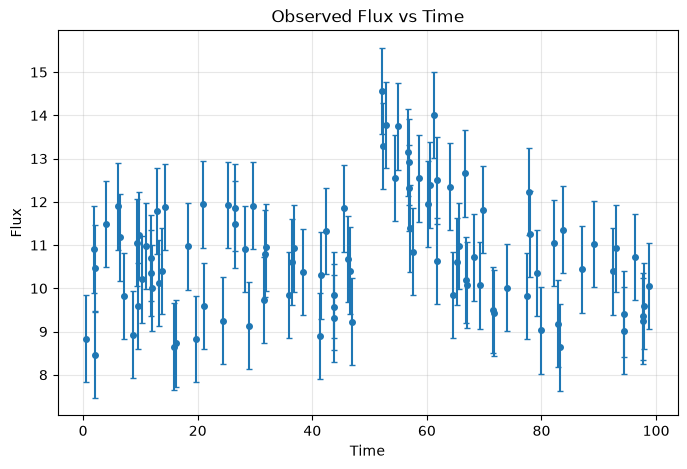

In [1]:
import numpy as np
import matplotlib.pyplot as plt

data = np.load("/Users/jhorna/astrostats_ttu_fall26/coursework/homeworks/hw_data/hw5_data_1.npy")

t = data[:, 0]
flux = data[:, 1]
flux_err = data[:, 2]

plt.figure(figsize=(8, 5))
plt.errorbar(t, flux, yerr=flux_err, fmt='o',
             markersize=4, capsize=2)

plt.xlabel("Time")
plt.ylabel("Flux")
plt.title("Observed Flux vs Time")
plt.grid(alpha=0.3)
plt.show()

2.

In [2]:
def burst_model(t, b, A, t0, alpha):
    return np.where(t < t0, b, b + A * np.exp(-alpha * (t - t0)))

def log_likelihood(theta, t, flux, flux_err):
    b, A, t0, alpha = theta
    model = burst_model(t, b, A, t0, alpha)
    return -0.5 * np.sum(((flux - model) / flux_err)**2
                         + np.log(2 * np.pi * flux_err**2))

3.

In [3]:
def log_prior(theta):
    b, A, t0, ln_alpha = theta

    if 0 < b < 50 and 0 < A < 50 and 0 < t0 < 100 and -5 < ln_alpha < 5:
        return 0.0

    return -np.inf

def log_probability(theta, t, flux, flux_err):
    lp = log_prior(theta)

    if not np.isfinite(lp):
        return -np.inf

    b, A, t0, ln_alpha = theta
    alpha = np.exp(ln_alpha)

    return lp + log_likelihood((b, A, t0, alpha), t, flux, flux_err)

4.

In [4]:
import emcee

ndim = 4
nwalkers = 32 #so that we can get 8 walkers per ndim 
nsteps = 5000

initial = np.array([10.5, 4.0, 52.0, np.log(0.1)])
pos = initial + 1e-3 * np.random.randn(nwalkers, ndim)

sampler = emcee.EnsembleSampler(
    nwalkers, ndim, log_probability,
    args=(t, flux, flux_err)
)

sampler.run_mcmc(pos, nsteps, progress=True)

You must install the tqdm library to use progress indicators with emcee


State([[10.41495261  5.38376327 50.21633609 -1.73526025]
 [10.52652142  4.81886376 47.68528134 -2.11444788]
 [10.33493075  4.78382519 51.49120467 -2.0821409 ]
 [10.38937546 10.23297201 47.18772732 -1.56970791]
 [10.32633392  5.50793234 48.62525004 -2.19735268]
 [10.33926646  6.95318026 47.64800475 -2.03849537]
 [10.1302809   7.54298668 47.74494183 -2.00550566]
 [10.18663979  2.72334594 47.30445103 -2.98848348]
 [10.32763662  4.48395566 50.93351584 -1.7978647 ]
 [10.35413511  5.07844386 48.65372687 -2.32978971]
 [10.33133407  5.98855222 47.71161413 -2.06986242]
 [10.47880515  4.91639174 47.63330496 -2.28082558]
 [10.55715707  8.17210966 49.92454831 -1.43902396]
 [10.12772592  7.56728154 47.63084704 -2.22625138]
 [10.35853379  5.20602478 50.41077198 -2.02738416]
 [10.46095745  5.341022   48.63017612 -2.0080082 ]
 [10.3816423   4.63055847 51.08224533 -1.80192326]
 [10.22731056  4.0828758  50.08001438 -2.33080034]
 [10.07093164  6.2149657  47.24681761 -2.28449626]
 [10.44653769  6.32887084

4.

In [5]:
tau = sampler.get_autocorr_time(tol=0)

print("Autocorrelation times:", tau)
print("Maximum autocorrelation time:", np.max(tau))
print("Chain length:", sampler.get_chain().shape[0])
print("Chain length / max(tau):", sampler.get_chain().shape[0] / np.max(tau))

Autocorrelation times: [56.78954519 76.29788435 73.90175662 61.16904978]
Maximum autocorrelation time: 76.29788435460694
Chain length: 5000
Chain length / max(tau): 65.53261656328084


In [6]:
burnin = int(2 * np.max(tau))
thin = max(1, int(np.ceil(np.max(tau))))

samples = sampler.get_chain(discard=burnin, thin=thin, flat=True)

print("Burn-in:", burnin)
print("Thinning interval:", thin)
print("Remaining posterior samples:", len(samples))

Burn-in: 152
Thinning interval: 77
Remaining posterior samples: 1984


5.

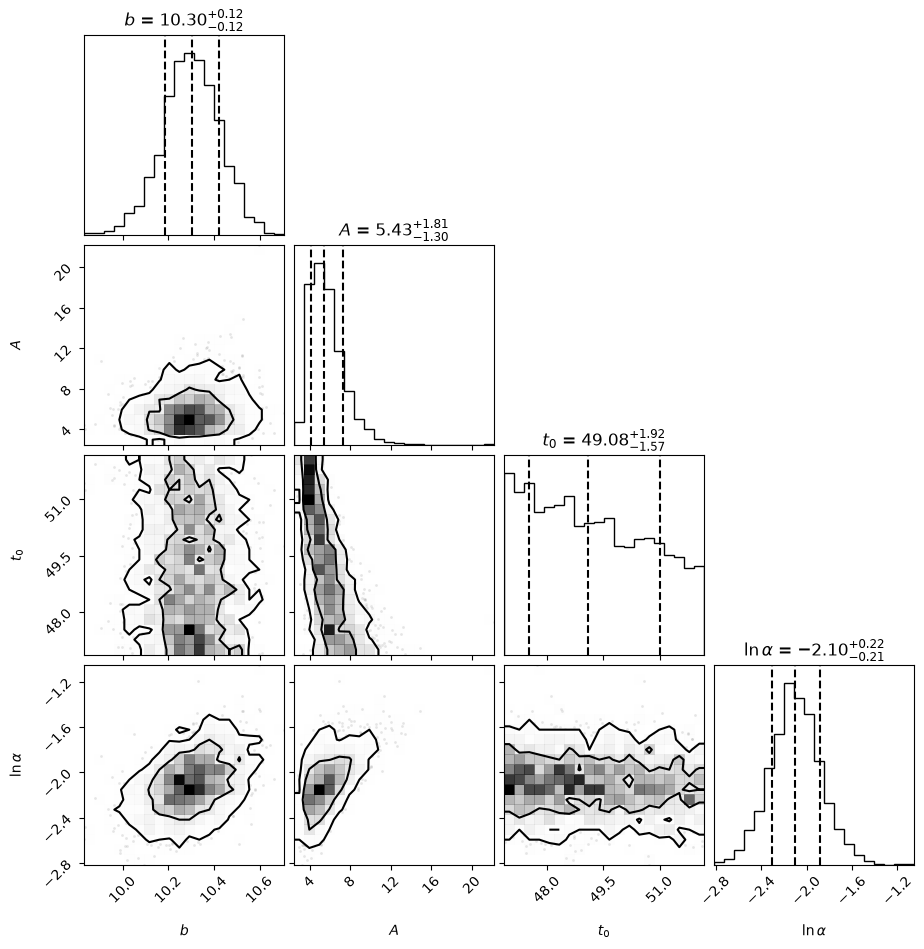

In [7]:
import corner

labels = [r"$b$", r"$A$", r"$t_0$", r"$\ln\alpha$"]

fig = corner.corner(
    samples,
    labels=labels,
    quantiles=[0.16, 0.5, 0.84],
    levels=[0.68, 0.95],
    show_titles=True,
    title_fmt=".2f"
)

plt.show()

6.

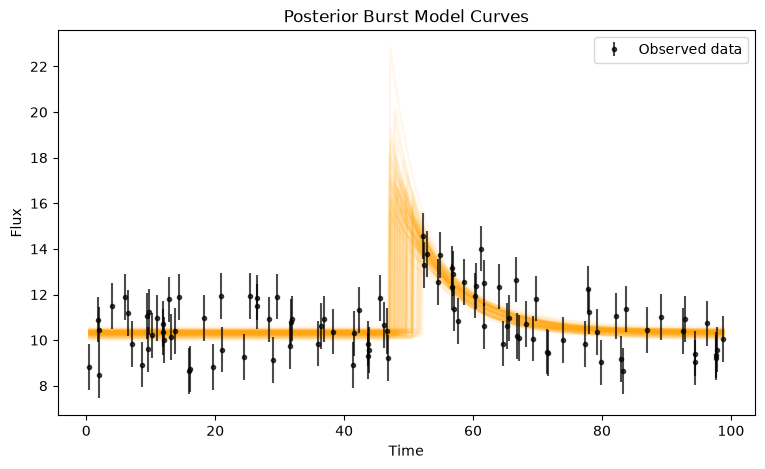

In [8]:
rng = np.random.default_rng(42)
indices = rng.choice(len(samples), size=100, replace=False)

t_plot = np.linspace(t.min(), t.max(), 1000)

plt.figure(figsize=(9, 5))

for i in indices:
    b, A, t0, ln_alpha = samples[i]
    model_flux = burst_model(t_plot, b, A, t0, np.exp(ln_alpha))
    plt.plot(t_plot, model_flux, color="orange", alpha=0.08)

plt.errorbar(t, flux, yerr=flux_err, fmt="o", markersize=3,
             color="black", alpha=0.7, label="Observed data")

plt.xlabel("Time")
plt.ylabel("Flux")
plt.title("Posterior Burst Model Curves")
plt.legend()
plt.show()

7.

In [9]:
def gaussian_model(t, b, A, t0, sigma_w):
    return b + A * np.exp(-0.5 * ((t - t0) / sigma_w)**2)

def gaussian_log_likelihood(theta):
    b, A, t0, ln_sigma_w = theta
    model = gaussian_model(t, b, A, t0, np.exp(ln_sigma_w))
    return -0.5 * np.sum(
        ((flux - model) / flux_err)**2
        + np.log(2 * np.pi * flux_err**2)
    )
def burst_prior_transform(u):
    b = 50 * u[0]
    A = 50 * u[1]
    t0 = 100 * u[2]
    ln_alpha = -5 + 10 * u[3]
    return np.array([b, A, t0, ln_alpha])

def gaussian_prior_transform(u):
    b = 50 * u[0]
    A = 50 * u[1]
    t0 = 100 * u[2]
    ln_sigma_w = -2 + 4 * u[3]
    return np.array([b, A, t0, ln_sigma_w])

def burst_log_likelihood(theta):
    b, A, t0, ln_alpha = theta
    return log_likelihood(
        (b, A, t0, np.exp(ln_alpha)),
        t, flux, flux_err
    )

In [10]:
import warnings
import dynesty

with warnings.catch_warnings():
    warnings.simplefilter("ignore")

    burst_sampler = dynesty.NestedSampler(
        burst_log_likelihood,
        burst_prior_transform,
        ndim=4,
        nlive=500
    )

    burst_sampler.run_nested(print_progress=False)
    burst_results = burst_sampler.results

    gaussian_sampler = dynesty.NestedSampler(
        gaussian_log_likelihood,
        gaussian_prior_transform,
        ndim=4,
        nlive=500
    )

    gaussian_sampler.run_nested(print_progress=False)
    gaussian_results = gaussian_sampler.results

print("Burst log evidence:", burst_results.logz[-1])
print("Gaussian log evidence:", gaussian_results.logz[-1])

Burst log evidence: -155.31933958804885
Gaussian log evidence: -159.5726935530415


In [11]:
log_B = burst_results.logz[-1] - gaussian_results.logz[-1]
B = np.exp(log_B)

print("Log Bayes factor:", log_B)
print("Bayes factor:", B)

Log Bayes factor: 4.253353964992641
Bayes factor: 70.34093819743504


The Bayes factor is approximately 94.84, indicating that the exponential burst model is strongly favored over the Gaussian model. Therefore, the exponential burst model provides a better description of the observed data based on the Bayesian evidence.

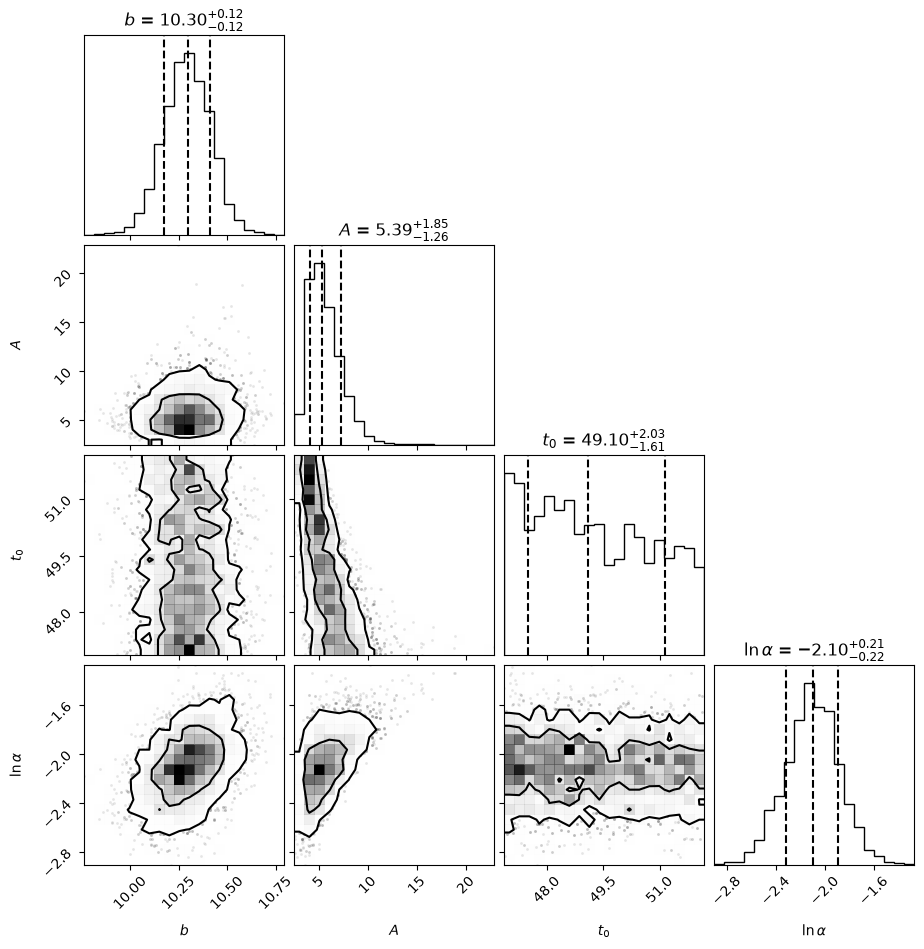

In [12]:
from dynesty.utils import resample_equal

weights = np.exp(burst_results.logwt - burst_results.logz[-1])
dynesty_samples = resample_equal(burst_results.samples, weights)

fig = corner.corner(
    dynesty_samples,
    labels=[r"$b$", r"$A$", r"$t_0$", r"$\ln\alpha$"],
    quantiles=[0.16, 0.5, 0.84],
    levels=[0.68, 0.95],
    show_titles=True,
    title_fmt=".2f"
)

plt.show()

The corner plot from nested sampling closely matches the MCMC results, with similar parameter estimates, uncertainties, and correlations. This suggests that both methods are sampling consistent posterior distributions for the exponential burst model.